# Introduction
This project’s goal is to determine what the best neighborhood in Pittsburgh is by looking at the metric of safety. Our approach was to analyze public data sets about various topics regarding the city that all play a part in how safe the city is. We came up with the safety metric because everything else branches from safety. In our minds, we thought that if you are living in a neighborhood with a lot of crime or accidents and no responsiveness, then it would be unfit to live in. Therefore, after we looked at and combined all of our data, we looked for which neighborhood was able to hold the best against our metric for each category. Alternative metrics we discussed was the quality of life for pets and nearby cultural locations like restaurants and activities. We chose to go with safety because that had the best data representation on the public data website.
# Metric
There is a lot that could go into the safety metric but it was beyond the scope of this project to look at dozens of data sets to discuss everything from snow, landslides, animals, traffic, police, the data sets we used, and anything else related to safety. We decided to use the submetrics of arrests, crime reports, ems districts, and fire incidents. We chose these because they are relevant to safety and all had strong data sets that we could get a lot of information from. One thing to note is that crime reports and arrests may seem similar but we wanted to understand how often justice was served after a crime occurred. 


# Access to Emergency Medical Services (Nathan Pozzuto)

The data within EMS.cvs lists the 20 EMS stations that service the neighborhoods of pittsburgh with their corresponding service districts. The 14 EMS districts in the City of Pittsburgh are geographic response territories assigned to specific Medic stations operated by the Pittsburgh Bureau of Emergency Medical Services. Each district ensures rapid Advanced Life Support (ALS) ambulance dispatch, pre-hospital medical care, and technical rescue coverage across all 90 city neighborhoods. My statistical analysis will compare the area that each station services (excluding district 13) to determine which neighborhood has the best access to emergency medical services.

![EMS districts](pittsburgh_ems_districts-2.png)

## Area
The area is important for determining the coverage by emergency medical services because a bigger area means that the station has to cover more physical space on average for each call. However, this is not the whole picture.

Note: Some districts are listed more than once because these are all graphs of the region that a single station covers and some distrcits have multiple stations.

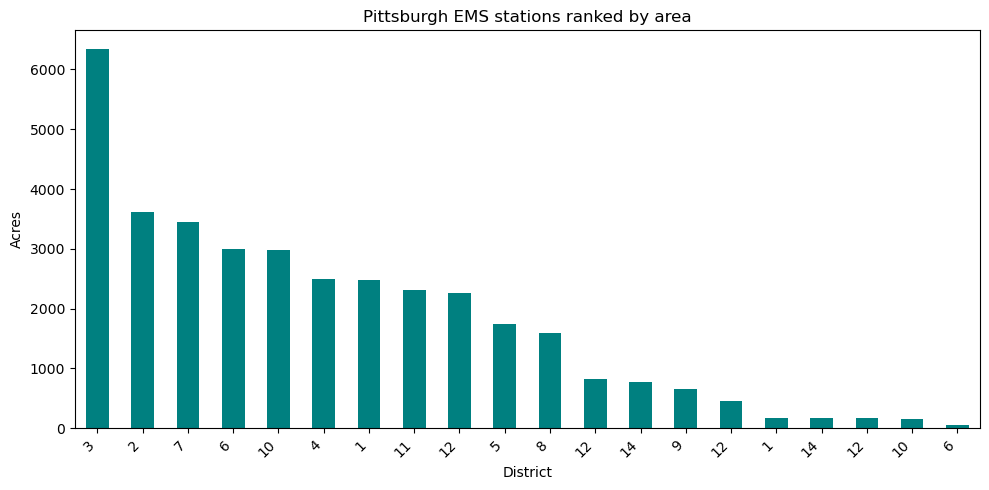

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("EMS.csv")
ranked = df.sort_values("acres", ascending=False)

ax = ranked.plot.bar(
    x="district",
    y="acres",
    legend=False,
    figsize=(10, 5),
    color="teal",
)
ax.set_title("Pittsburgh EMS stations ranked by area")
ax.set_xlabel("District")
ax.set_ylabel("Acres")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Perimeter
On top of area, perimeter is also important because it gives a better idea of the shape of the coverage zone. For example, a perfect circle would have the lowest perimeter for a given area so that is ideal for a equally distributed district. Having a much larger perimeter shows that the shape is more irregular.

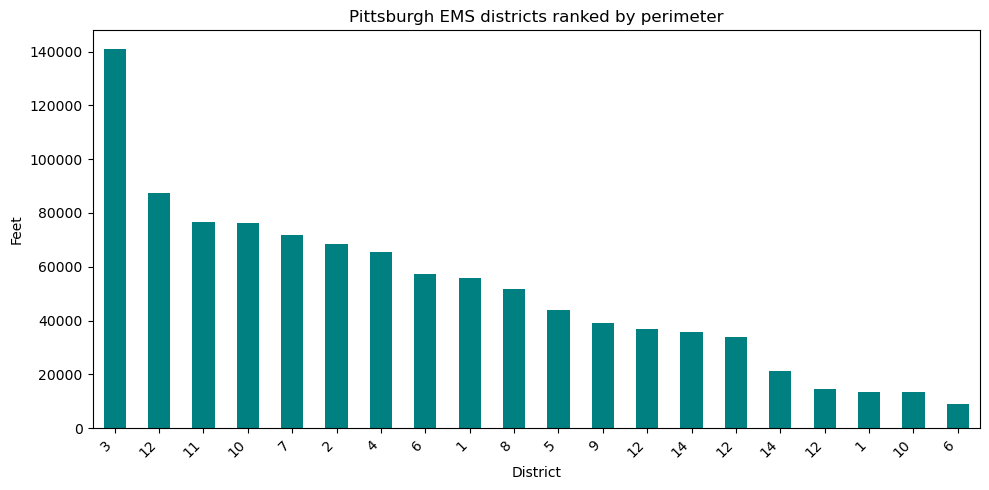

In [8]:
ranked = df.sort_values("perimeter", ascending=False)

ax = ranked.plot.bar(
    x="district",
    y="perimeter",
    legend=False,
    figsize=(10, 5),
    color="teal",
)
ax.set_title("Pittsburgh EMS districts ranked by perimeter")
ax.set_xlabel("District")
ax.set_ylabel("Feet")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Combined Metric
The code below combines the area column and perimeter column for each district to calculate a general coverage score including all stations in a district. This coverage score is essentially the "goodness percentage" and will be added to the group's final evaluation for each neighborhood.

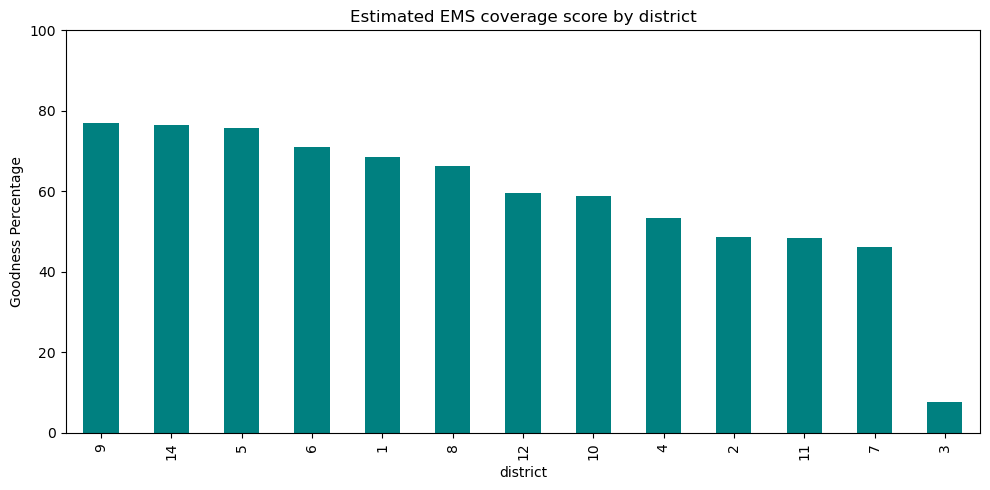

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("EMS.csv")

##both in feet
# One row per station, so combine rows into one row per district
def combine(g):
    n_stations = len(g)
    # If every station row repeats the same district area/perimeter, count it once.
    # If the values differ by row, they are separate pieces, so add them up.
    if g["area"].nunique() == 1:
        area = g["area"].iloc[0]
        perimeter = g["perimeter"].iloc[0]
    else:
        area = g["area"].sum()
        perimeter = g["perimeter"].sum()
    return pd.Series({"area": area, "perimeter": perimeter, "stations": n_stations})

districts = df.groupby("district").apply(combine, include_groups=False).reset_index()

area = districts["area"]
perimeter = districts["perimeter"]
stations = districts["stations"]

def scale(s, higher_is_better=True):
    rng = s.max() - s.min()
    s = (s - s.min()) / rng if rng != 0 else s * 0 + 0.5   # avoid dividing by zero
    return (s if higher_is_better else 1 - s) * 100

# Distance part: average distance from the nearest station.
# Each station is assumed to cover an equal share of the district's area.
area_per_station = area / stations
avg_dist = (2 / 3) * np.sqrt(area_per_station / np.pi)
distance_score = scale(avg_dist, higher_is_better=False)

# Shape part: compactness of the whole district, 1.0 = perfect circle
compactness = 4 * np.pi * area / perimeter**2
shape_score = scale(compactness, higher_is_better=True)

districts["coverage_score"] = (0.7 * distance_score + 0.3 * shape_score).round(1)

ranked = districts.sort_values("coverage_score", ascending=False)
##print(ranked[["district", "coverage_score"]])

ax = ranked.plot.bar(x="district", y="coverage_score", legend=False,
                     figsize=(10, 5), color="teal")
ax.set_ylim(0, 100)
ax.set_ylabel("Goodness Percentage")
ax.set_title("Estimated EMS coverage score by district")
plt.tight_layout()
plt.show()
district_score = districts.set_index(districts["district"].astype(str))["coverage_score"]

In [15]:
import numpy as np

all_neighborhoods = [
    "Allegheny Center", "Allegheny West", "Allentown", "Arlington", "Arlington Heights",
    "Banksville", "Bedford Dwellings", "Beechview", "Beltzhoover", "Bloomfield", "Bluff",
    "Bon Air", "Brighton Heights", "Brookline", "California-Kirkbride", "Carrick",
    "Central Business District", "Central Lawrenceville", "Central North Side",
    "Central Oakland", "Chartiers City", "Chateau", "Crafton Heights", "Crawford-Roberts",
    "Duquesne Heights", "East Allegheny", "East Carnegie", "East Hills", "East Liberty",
    "Elliott", "Esplen", "Fairywood", "Fineview", "Friendship", "Garfield", "Glen Hazel",
    "Greenfield", "Hays", "Hazelwood", "Highland Park", "Homewood North", "Homewood South",
    "Homewood West", "Knoxville", "Larimer", "Lincoln Place", "Lincoln-Lemington-Belmar",
    "Lower Lawrenceville", "Manchester", "Marshall-Shadeland", "Middle Hill", "Morningside",
    "Mt. Oliver", "Mt. Washington", "New Homestead", "North Oakland", "North Shore",
    "Northview Heights", "Oakwood", "Overbrook", "Perry North", "Perry South", "Point Breeze",
    "Point Breeze North", "Polish Hill", "Regent Square", "Ridgemont", "Shadyside", "Sheraden",
    "South Oakland", "South Shore", "South Side Flats", "South Side Slopes", "Spring Garden",
    "Spring Hill-City View", "Squirrel Hill North", "Squirrel Hill South", "St. Clair",
    "Stanton Heights", "Strip District", "Summer Hill", "Swisshelm Park", "Terrace Village",
    "Troy Hill", "Upper Hill", "Upper Lawrenceville", "West End", "West Oakland", "Westwood",
    "Windgap",
]

district_neighborhoods = {
    "1":  ["Homewood North", "Homewood South", "Homewood West", "Lincoln-Lemington-Belmar",
           "Larimer", "East Liberty", "Highland Park"],
    "2":  ["Knoxville", "Bon Air", "Allentown", "Mt. Oliver", "Carrick", "Brookline", "Overbrook"],
    "3":  ["West End", "Beechview", "Banksville", "Mt. Washington", "Oakwood", "Westwood",
           "East Carnegie", "Elliott", "Sheraden", "Chartiers City"],
    "4":  ["Allegheny Center", "Allegheny West", "Central North Side", "Northview Heights",
           "Fineview", "Spring Hill-City View", "Perry South"],
    "5":  ["Crawford-Roberts", "Middle Hill", "Upper Hill", "South Oakland", "Central Oakland",
           "Polish Hill"],
    "6":  ["Garfield", "Central Lawrenceville", "Lower Lawrenceville", "Upper Lawrenceville",
           "Bloomfield", "Highland Park", "Stanton Heights", "Morningside"],
    "7":  ["Greenfield", "Squirrel Hill South", "Hazelwood", "Swisshelm Park"],
    "8":  ["Beltzhoover", "Mt. Washington", "South Side Flats", "South Side Slopes",
           "Arlington", "Arlington Heights"],
    "9":  ["Shadyside", "North Oakland", "Bloomfield", "East Liberty"],
    "10": ["Marshall-Shadeland", "Manchester", "Brighton Heights", "Perry North", "Summer Hill"],
    "12": ["Hays", "Lincoln Place", "St. Clair", "Hazelwood", "Glen Hazel", "New Homestead"],
    "14": ["Central Business District", "Bluff"],
}

# assumed districts for neighborhoods not located in the district
assumed = {
    "Bedford Dwellings": "5", "Terrace Village": "5", "West Oakland": "5",
    "California-Kirkbride": "4", "East Allegheny": "4", "North Shore": "4",
    "Spring Garden": "4", "Troy Hill": "4",
    "Chateau": "10",
    "Crafton Heights": "3", "Esplen": "3", "Fairywood": "3", "Ridgemont": "3", "Windgap": "3",
    "Duquesne Heights": "8", "South Shore": "8",
    "East Hills": "1", "Point Breeze North": "1",
    "Friendship": "9",
    "Point Breeze": "7", "Regent Square": "7", "Squirrel Hill North": "7",
    "Strip District": "6",
}

# Table of info per neighborhood
membership = {}   # neighborhood -> list of district keys
for k, names in district_neighborhoods.items():
    for n in names:
        membership.setdefault(n, []).append(k)

rows = []
for n in all_neighborhoods:
    if n in membership:
        ds, source = membership[n], "EMS list"
    elif n in assumed:
        ds, source = [assumed[n]], "assumed"
    else:
        ds, source = [], "missing"
    scores = [district_score[k] for k in ds if k in district_score.index]
    rows.append({"neighborhood": n,
                 "districts": ", ".join(ds),
                 "source": source,
                 "score": round(float(np.mean(scores)), 1) if scores else np.nan})

neighborhood_df = (pd.DataFrame(rows)
                   .sort_values("score", ascending=False)
                   .reset_index(drop=True))
neighborhood_scores = dict(zip(neighborhood_df["neighborhood"], neighborhood_df["score"]))

print(len(neighborhood_df), "neighborhoods,", neighborhood_df["score"].isna().sum(), "without a score")
print(neighborhood_df.to_string())

90 neighborhoods, 0 without a score
                 neighborhood districts    source  score
0               North Oakland         9  EMS list   77.0
1                  Friendship         9   assumed   77.0
2                   Shadyside         9  EMS list   77.0
3   Central Business District        14  EMS list   76.4
4                       Bluff        14  EMS list   76.4
5             Central Oakland         5  EMS list   75.7
6                 Middle Hill         5  EMS list   75.7
7            Crawford-Roberts         5  EMS list   75.7
8           Bedford Dwellings         5   assumed   75.7
9                  Upper Hill         5  EMS list   75.7
10               West Oakland         5   assumed   75.7
11                Polish Hill         5  EMS list   75.7
12              South Oakland         5  EMS list   75.7
13            Terrace Village         5   assumed   75.7
14                 Bloomfield      6, 9  EMS list   74.0
15               East Liberty      1, 9  EMS list   

## EMS Conclusion

Overall, when EMS access is quantified by compactness and shape as functions of area and perimeter, districts 9, 14, 5 score the best. After also accounting for neighborhoods not listed and neighborhoods listed twice, the table above scores each neighborhood. The neighborhoods with the best access to emergency medical services according to these calculations are North Oakland, Friendship, and Shadyside. The worst were all tied because they are in the same district. The limitation of this metric is that there are other factors involved in EMS access like number of ambulances, the call volume, and the actual travel time based on roads. That being said, this data set gives a decent idea of how close you are to an EMS station.


# Introduction for Arrests (Ayden Kern)

I chose to do the police arrests in the city of Pittsburgh from 2016 to 2023. This dataset will allow me to determine which neighborhood has the most arrests occuring in them, which showcases the city with the most responding police units and the most dangerous people (in theory this is what it means, but it may not be related). The neighborhood with the least amount of arrests will be seen as the safest as it has the least action in terms of crime.

90 neighborhoods, 63,486 arrests


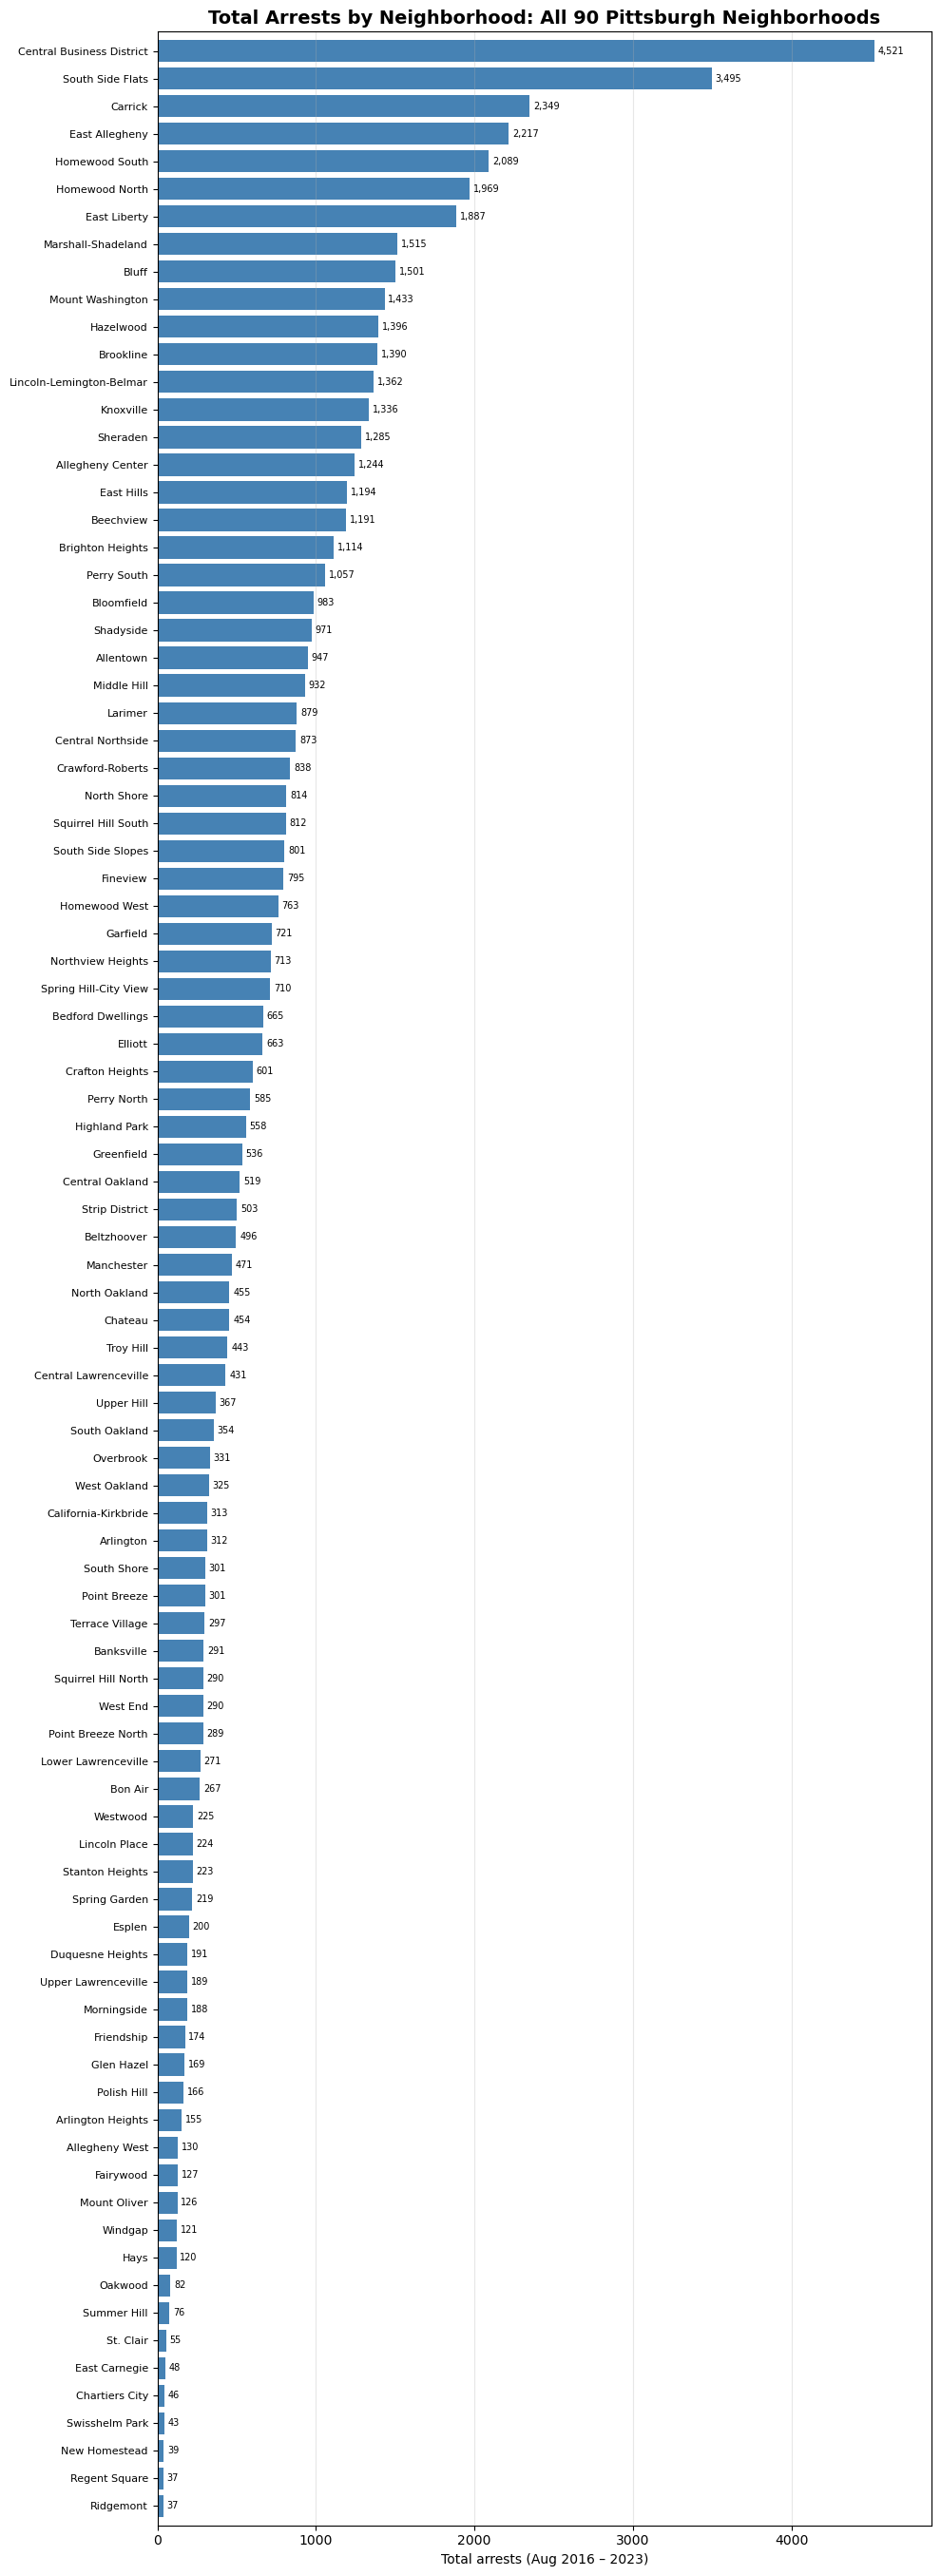

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Crime_Arrests.csv"

# Load & clean
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
df["ARRESTTIME"] = pd.to_datetime(df["ARRESTTIME"], errors="coerce")
df["year"] = df["ARRESTTIME"].dt.year
df = df.dropna(subset=["INCIDENTNEIGHBORHOOD", "year"])
df["year"] = df["year"].astype(int)
df = df[df["year"] >= 2016]

#This is combining areas into distinct neighborhoods so only 90 are represented,
#not the 98 included in the file.
merge = {
    "Central North Side": "Central Northside",
    "Golden Triangle/Civic Arena": "Central Business District",
    "Troy Hill-Herrs Island": "Troy Hill",
    "Mt. Oliver Neighborhood": "Mount Oliver",
}
df["neighborhood"] = df["INCIDENTNEIGHBORHOOD"].replace(merge)

#Drop labels that are not Pittsburgh neighborhoods
drop = ["Outside City", "Outside County", "Outside State", "Mt. Oliver Boro"]
df = df[~df["neighborhood"].isin(drop)]

totals = df["neighborhood"].value_counts()
print(f"{len(totals)} neighborhoods, {totals.sum():,} arrests")
assert len(totals) == 90

#Plot all 90, highest to lowest, top to bottom
plot_totals = totals.sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 0.28 * len(plot_totals) + 2))
ax.barh(plot_totals.index, plot_totals.values, color="steelblue")
for y, v in enumerate(plot_totals.values):
    ax.text(v + totals.max() * 0.005, y, f"{v:,}", va="center", fontsize=7)
ax.set_xlim(0, totals.max() * 1.08)
ax.set_ylim(-0.7, len(plot_totals) - 0.3)
ax.tick_params(axis="y", labelsize=8)
ax.set_xlabel("Total arrests (Aug 2016 – 2023)")
ax.set_title("Total Arrests by Neighborhood: All 90 Pittsburgh Neighborhoods",
             fontsize=14, weight="bold")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
import pandas as pd

CSV_PATH = "Crime_Arrests.csv"
MAX_ARRESTS = 5000         

# Load & clean
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
df["ARRESTTIME"] = pd.to_datetime(df["ARRESTTIME"], errors="coerce")
df["year"] = df["ARRESTTIME"].dt.year
df = df.dropna(subset=["INCIDENTNEIGHBORHOOD", "year"])
df["year"] = df["year"].astype(int)
df = df[df["year"] >= 2016]

#Reduce to Pittsburgh's 90 official neighborhoods
merge = {
    "Central North Side": "Central Northside",
    "Golden Triangle/Civic Arena": "Central Business District",
    "Troy Hill-Herrs Island": "Troy Hill",
    "Mt. Oliver Neighborhood": "Mount Oliver",
}
df["neighborhood"] = df["INCIDENTNEIGHBORHOOD"].replace(merge)
drop = ["Outside City", "Outside County", "Outside State", "Mt. Oliver Boro"]
df = df[~df["neighborhood"].isin(drop)]

#Total arrests per neighborhood
totals = df["neighborhood"].value_counts()

#Linear safety score: 0 arrests = 100%, MAX_ARRESTS or more = 0%
safety = (100 * (1 - totals / MAX_ARRESTS)).clip(lower=0, upper=100).round(1)

#Dictionary: {neighborhood: safety %}
safety_dict = safety[totals.sort_values(kind="stable").index].to_dict()

#Rank-based score (100 = fewest arrests, 0 = most)
percentile = (100 * (1 - (totals.rank(method="min") - 1) / (len(totals) - 1))).round(1)

#Table with everything together
table = pd.DataFrame({
    "arrests": totals,
    "safety_score_pct": safety,
    "safety_percentile": percentile,
}).sort_values(["arrests"], kind="stable")
table.index.name = "neighborhood"

print(len(safety_dict), "neighborhoods")
print(table.to_string())
table.to_csv("neighborhood_safety_scores.csv")

90 neighborhoods
                           arrests  safety_score_pct  safety_percentile
neighborhood                                                           
Regent Square                   37              99.3              100.0
Ridgemont                       37              99.3              100.0
New Homestead                   39              99.2               97.8
Swisshelm Park                  43              99.1               96.6
Chartiers City                  46              99.1               95.5
East Carnegie                   48              99.0               94.4
St. Clair                       55              98.9               93.3
Summer Hill                     76              98.5               92.1
Oakwood                         82              98.4               91.0
Hays                           120              97.6               89.9
Windgap                        121              97.6               88.8
Mount Oliver                   126             

# Safety Values
These values that have been created are to judge each neighborhood on overall safety and protection. The Safety Score itself is on a scale of 0-100%, where 100% would be 0 arrests and 5,000+ arrests would be 0%. The Safety Percentile is based on the neighborhood's safety score relative to other neighborhoods. All neighborhoods and their arrest counts are listed as well. 

# Conclusion (For Arrests)
After looking at these graphs, it shows us a clear and easy to see visualization of the data. Based on all of the arrests throughout the years, both Regent Square and Ridgemont only had 37 arrests, making them look like the clear and easy "safest" neighborhoods. However, on the opposite end, Central Business District has the most arrests at 4,521 throughout these years. While that is a drastically high number compared to 37, it showcases the responsiveness of the police force, making it the most responsive neighborhood. Overall, I would still say and believe that Regent Square and Ridgemont are marked the safest neighborhoods with the least number of arrests in these 7 years. My safest neighborhoods are Regent Square and Ridgemont, based on my sub-metric. The most responsive neighborhood I believe is the Central Business District, with the most arrests.

# Criminal Activity Reports (Ivan Li)
The Monthly Criminal Activity dataset tracks the instances of police reports each month from the year 2024 to 2026. Here we will analyze the data to determine the neighborhood with the highest crime rate. Each row of the dataset details the date, time, type, and location of the crime occurred.

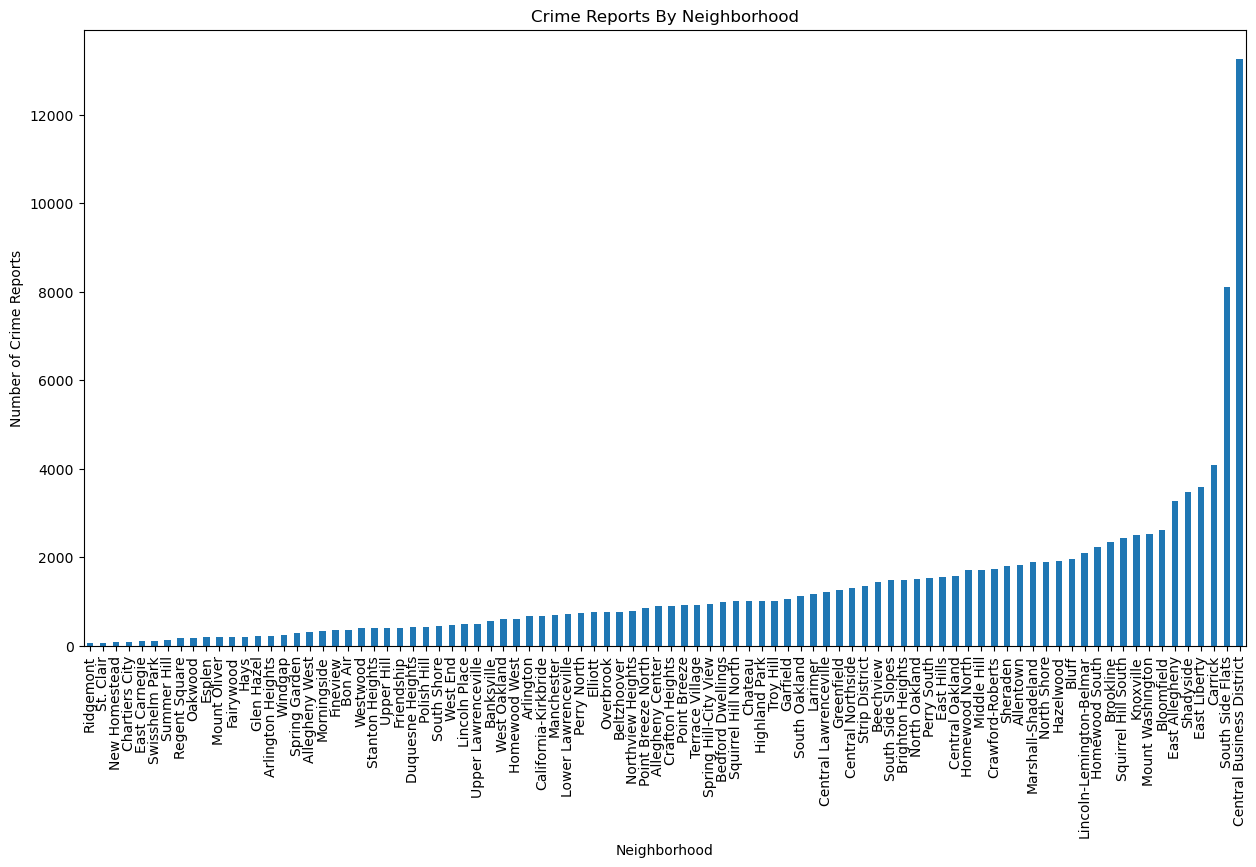

In [1]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as py

crimeData = pd.read_csv("MonthlyCrime2024-26.csv", low_memory = False)

# Fix double hyphens to single hyphens
crimeData["Neighborhood"] = crimeData["Neighborhood"].str.replace("–", "-", regex=False)

totalCrime = crimeData.groupby("Neighborhood").count()["NIBRS_Offense_Category"].sort_values(ascending = True)
totalCrime.plot(title = "Crime Reports By Neighborhood",kind = "bar", figsize = (15,8), ylabel = "Number of Crime Reports")
plt.show()

In [2]:
# display 5 most crimes and 5 least crimes
totalCrime

Neighborhood
Ridgemont                       56
St. Clair                       63
New Homestead                   83
Chartiers City                  88
East Carnegie                  103
                             ...  
Shadyside                     3481
East Liberty                  3582
Carrick                       4080
South Side Flats              8101
Central Business District    13259
Name: NIBRS_Offense_Category, Length: 90, dtype: int64

In [3]:
monthCrime = pd.DataFrame(crimeData).dropna()
# create dictionary
crimeType = {}

# iterate through each row of data frame
for index, row in monthCrime.iterrows():
    # collect crime type from data frame 
    crime = row['NIBRS_Offense_Type']

    # check if item is in dict; if so increment occurence by 1, otherwise create new key value pair
    if crime in crimeType:
        crimeType[crime] += 1
    else:
        crimeType[crime] = 1

# display dict in alphabetical order
for key, value in sorted(crimeType.items()):
    print(f"{key}: {value}")

Aggravated Assault: 2617
All Other Larceny: 4411
All other Offenses: 6205
Arson: 349
Assisting or Promoting Prostitution: 47
Bad Checks: 73
Bribery: 2
Burglary/Breaking & Entering: 2216
Commercial Sex Acts: 4
Counterfeiting/Forgery: 383
Credit Card/ATM Fraud: 1883
Curfew/Loiting/Vagrancy Violations: 265
Destruction/Damage/Vandalism of Property: 8304
Disorderly Conduct: 5451
Driving Under the Influence: 1308
Drug Equipment Violations: 3460
Drug/Narcotic Violations: 5881
Drunkenness: 618
Embezzlement: 12
Extortion/Blackmail: 161
False Pretenses/Swindle/Confidence Game: 1458
Family Offenses, Nonviolent: 436
Hacking/Computer Invasion: 62
Impersonation: 1235
Intimidation: 6383
Involuntary Servitude: 2
Kidnapping/Abduction: 235
Liquor Law Violaitons: 47
Motor Vehicle Theft: 3240
Murder & Nonnegligent Manslaughter: 101
Negligent Manslaughter: 6
Not NIBRS Reportable: 18512
Peeping Tom: 9
Pocket-Picking: 72
Pornography/Obscene Material: 102
Prostitution: 42
Purse-snatching: 93
Robbery: 1139
Sho

[Insert Severity Section]

In [4]:
totalCrime_df = totalCrime.to_frame(name="Crime_Count").reset_index()

print(f"{'Neighborhood':<25} | {'Result':>10}")
print("-" * 38)

for neighborhood, count in zip(totalCrime_df["Neighborhood"], totalCrime_df["Crime_Count"]):
    result = 1 - (int(count) / 13259)
    print(f"{neighborhood:<25} | {result:>10.4f}")

Neighborhood              |     Result
--------------------------------------
Ridgemont                 |     0.9958
St. Clair                 |     0.9952
New Homestead             |     0.9937
Chartiers City            |     0.9934
East Carnegie             |     0.9922
Swisshelm Park            |     0.9915
Summer Hill               |     0.9897
Regent Square             |     0.9867
Oakwood                   |     0.9867
Esplen                    |     0.9854
Mount Oliver              |     0.9851
Fairywood                 |     0.9850
Hays                      |     0.9847
Glen Hazel                |     0.9832
Arlington Heights         |     0.9828
Windgap                   |     0.9818
Spring Garden             |     0.9789
Allegheny West            |     0.9770
Morningside               |     0.9747
Fineview                  |     0.9735
Bon Air                   |     0.9732
Westwood                  |     0.9701
Stanton Heights           |     0.9701
Upper Hill               

# Conclusion

Ridgemont is the safest city based on the percentages given above. It has the least amount of crime incident reports compared to the rest, with a less severe aspect ratio in crime severity.

# Fire Incidents as a Sub-Metric for the Best Neighborhood in Pittsburgh (Ethan Hauber)

## Introduction
This data file analyzes building fire incidents from the WPRDC Fire Incidents dataset to help determine the best neighborhood in Pittsburgh. Lower numbers of building fires are treated as better for this sub-metric. The results will be combined with my group members’ crime and EMS metrics.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Fire_Incidents.csv')
print(df.shape)
df.head()

(10730, 19)


,_id,call_no,incident_type,type_description,address,alarms,alarm_time,primary_unit,census_tract,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone,latitude,longitude
0,1,F160029985,111.0,Building fire,"800 BLOCK CENTER ST, WILKINSBURG PA 15221",1,2016-04-21T05:01:04.000,231EN16,NaN,NaN,NaN,NaN,4.200356e+10,NaN,NaN,NaN,3-16,40.441275,-79.882485
1,2,F180022058,111.0,Building fire,"1100 BLOCK JANE ST, WILKINSBURG PA 15221",1,2018-03-13T08:34:43.000,231EN16,NaN,NaN,NaN,NaN,4.200356e+10,NaN,NaN,NaN,3-21,40.436342,-79.881003
2,3,F180022102,131.0,Passenger vehicle fire,"SB STATE HWY 28 SB AT 31S, PITTSBURGH PA 15212",0,2018-03-13T11:54:23.000,231EN32,2406.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1-1A,NaN,NaN
3,4,F170043431,131.0,Passenger vehicle fire,"1700 BLOCK BELLEAU DR, PITTSBURGH PA 15212",0,2017-05-31T08:39:47.000,231EN38,2509.0,Fineview,6.0,25.0,4.200325e+10,1.0,25.0,1.0,1-10,40.460303,-80.006980
4,5,F180021111,111.0,Building fire,"2400 BLOCK VILLAGE RD, PITTSBURGH PA 15205",1,2018-03-09T10:26:42.000,231EN31,2808.0,Fairywood,2.0,28.0,4.200356e+10,5.0,28.0,6.0,1-16,40.449009,-80.076607


In [2]:
# Columns and basic info
print(df.columns.tolist())
df.info()

# How many unique neighborhoods?
print(df['neighborhood'].nunique())
print(df['neighborhood'].value_counts(dropna=False).head(20))

# Incident types
print(df['type_description'].value_counts().head(15))

['_id', 'call_no', 'incident_type', 'type_description', 'address', 'alarms', 'alarm_time', 'primary_unit', 'census_tract', 'neighborhood', 'council_district', 'ward', 'tract', 'public_works_division', 'pli_division', 'police_zone', 'fire_zone', 'latitude', 'longitude']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10730 entries, 0 to 10729
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   _id                    10730 non-null  int64  
 1   call_no                10730 non-null  object 
 2   incident_type          10712 non-null  float64
 3   type_description       10730 non-null  object 
 4   address                10730 non-null  object 
 5   alarms                 10730 non-null  int64  
 6   alarm_time             10712 non-null  object 
 7   primary_unit           10724 non-null  object 
 8   census_tract           10076 non-null  float64
 9   neighborhood           9000 non-null   objec

In [3]:
# Drop rows with no neighborhood or non-Pittsburgh ones
df_clean = df[df['neighborhood'].notna() & (df['neighborhood'] != 'NA')].copy()

# Optional: keep only certain incident types (e.g. building fires)
# building_fires = df_clean[df_clean['incident_type'] == 111]

print(df_clean.shape)
print(df_clean['neighborhood'].value_counts().head(10))

(9000, 19)
neighborhood
Carrick                      328
South Side Flats             307
Central Business District    304
Squirrel Hill South          281
Hazelwood                    264
Mount Washington             238
East Liberty                 230
Brookline                    209
Homewood South               209
Lincoln-Lemington-Belmar     206
Name: count, dtype: int64


In [4]:
neighborhood_fires = df_clean.groupby('neighborhood').size().sort_values()
print(neighborhood_fires.head(10))   # lowest = fewer fires
print(neighborhood_fires.tail(10))   # highest

neighborhood
Mount Oliver Borough     7
Regent Square            9
East Carnegie           11
Mt. Oliver              12
Ridgemont               12
Arlington Heights       13
Oakwood                 13
St. Clair               15
Swisshelm Park          17
Chartiers City          18
dtype: int64
neighborhood
Lincoln-Lemington-Belmar     206
Homewood South               209
Brookline                    209
East Liberty                 230
Mount Washington             238
Hazelwood                    264
Squirrel Hill South          281
Central Business District    304
South Side Flats             307
Carrick                      328
dtype: int64


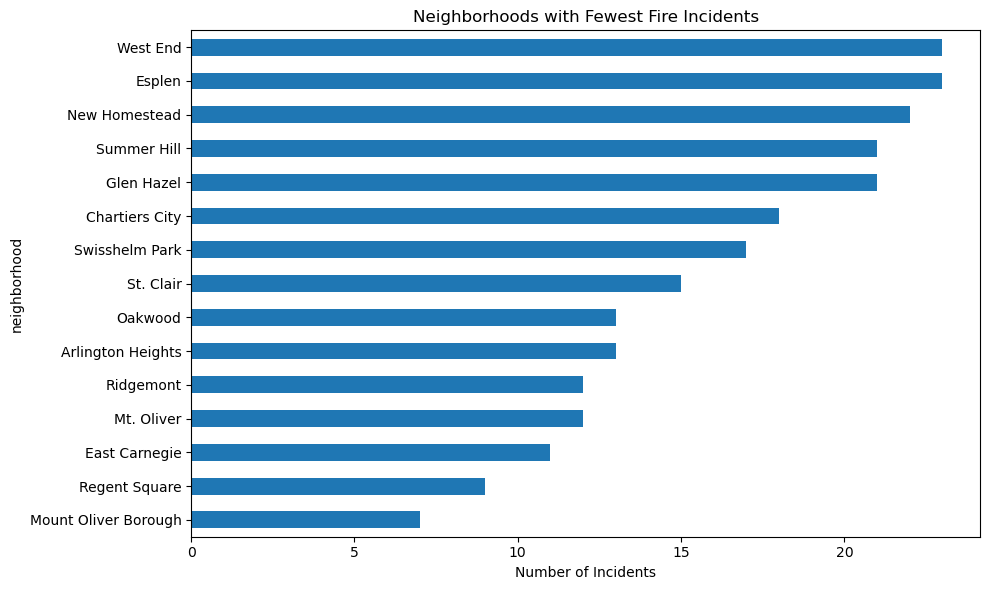

In [5]:
neighborhood_fires.head(15).plot(kind='barh', figsize=(10, 6), title='Neighborhoods with Fewest Fire Incidents')
plt.xlabel('Number of Incidents')
plt.tight_layout()
plt.show()

In [6]:
# Official Pittsburgh neighborhoods (partial list of the 90; expand as needed)
pittsburgh_neighborhoods = [
    'Allegheny Center', 'Allegheny West', 'Allentown', 'Arlington', 'Arlington Heights',
    'Banksville', 'Bedford Dwellings', 'Beechview', 'Beltzhoover', 'Bloomfield',
    'Bluff', 'Bon Air', 'Brighton Heights', 'Brookline', 'California-Kirkbride',
    'Carrick', 'Central Business District', 'Central Lawrenceville', 'Central Northside',
    'Central Oakland', 'Chartiers City', 'Chateau', 'Crafton Heights', 'Crawford-Roberts',
    'Duquesne Heights', 'East Allegheny', 'East Carnegie', 'East Hills', 'East Liberty',
    'Elliott', 'Esplen', 'Fairywood', 'Fineview', 'Friendship', 'Garfield', 'Glen Hazel',
    'Greenfield', 'Hays', 'Hazelwood', 'Highland Park', 'Homewood North', 'Homewood South',
    'Homewood West', 'Knoxville', 'Larimer', 'Lincoln-Lemington-Belmar', 'Lincoln Place',
    'Lower Lawrenceville', 'Manchester', 'Marshall-Shadeland', 'Middle Hill', 'Morningside',
    'Mount Oliver', 'Mount Washington', 'New Homestead', 'North Oakland', 'North Shore',
    'Northview Heights', 'Oakwood', 'Overbrook', 'Perry North', 'Perry South',
    'Point Breeze', 'Point Breeze North', 'Polish Hill', 'Regent Square', 'Ridgemont',
    'Shadyside', 'Sheraden', 'South Oakland', 'South Shore', 'South Side Flats',
    'South Side Slopes', 'Spring Garden', 'Spring Hill-City View', 'Squirrel Hill North',
    'Squirrel Hill South', 'St. Clair', 'Stanton Heights', 'Strip District',
    'Summer Hill', 'Swisshelm Park', 'Terrace Village', 'Troy Hill', 'Upper Hill',
    'Upper Lawrenceville', 'West End', 'West Oakland', 'Westwood', 'Windgap'
]

df_pgh = df_clean[df_clean['neighborhood'].isin(pittsburgh_neighborhoods)].copy()
print(df_pgh.shape)
print(df_pgh['neighborhood'].nunique())

(8981, 19)
89


In [7]:
# Recalculate on official Pittsburgh neighborhoods only
neighborhood_fires = df_pgh.groupby('neighborhood').size().sort_values()

print("Fewest incidents:")
print(neighborhood_fires.head(15))
print("\nMost incidents:")
print(neighborhood_fires.tail(10))

Fewest incidents:
neighborhood
Regent Square         9
East Carnegie        11
Ridgemont            12
Arlington Heights    13
Oakwood              13
St. Clair            15
Swisshelm Park       17
Chartiers City       18
Glen Hazel           21
Summer Hill          21
New Homestead        22
West End             23
Esplen               23
Bon Air              23
Hays                 24
dtype: int64

Most incidents:
neighborhood
Lincoln-Lemington-Belmar     206
Homewood South               209
Brookline                    209
East Liberty                 230
Mount Washington             238
Hazelwood                    264
Squirrel Hill South          281
Central Business District    304
South Side Flats             307
Carrick                      328
dtype: int64


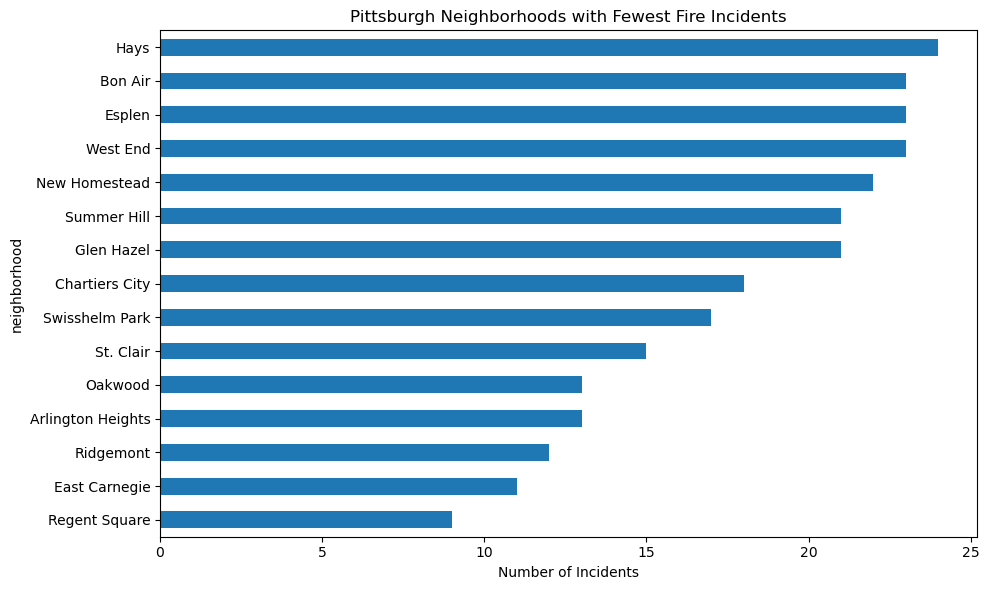

In [8]:
# Updated plot
neighborhood_fires.head(15).plot(
    kind='barh', 
    figsize=(10, 6), 
    title='Pittsburgh Neighborhoods with Fewest Fire Incidents'
)
plt.xlabel('Number of Incidents')
plt.tight_layout()
plt.show()

## The Metric
I am using the total number of **building fires** (incident type 111) per official Pittsburgh neighborhood. Building fires were chosen over all fire incidents because they are more serious and more relevant to neighborhood safety. Minor events (cooking fires, outside rubbish, vehicle fires, etc.) are excluded.

**Calculation:**
- Loaded the WPRDC Fire Incidents CSV
- Filtered to official Pittsburgh neighborhoods
- Kept only `incident_type == 111`
- Counted incidents by neighborhood

**Limitations**: The specific counts favor smaller neighborhoods; the data ends mid-2025; low counts mean small differences may not be highly meaningful.

In [10]:
# Building fires only (incident type 111)
building_fires = df_pgh[df_pgh['incident_type'] == 111]
building_counts = building_fires.groupby('neighborhood').size().sort_values()

print("Fewest building fires:")
print(building_counts.head(15))
print("\nMost building fires:")
print(building_counts.tail(10))
print(f"\nNeighborhoods with zero building fires: {(building_counts == 0).sum()}")

Fewest building fires:
neighborhood
New Homestead        1
Glen Hazel           1
St. Clair            1
Regent Square        1
Allegheny Center     2
Arlington Heights    2
East Carnegie        3
Friendship           3
West End             3
Swisshelm Park       3
Bon Air              3
Chateau              3
Hays                 4
Morningside          4
North Shore          4
dtype: int64

Most building fires:
neighborhood
East Liberty                46
Mount Washington            46
Perry South                 48
Beltzhoover                 50
Lincoln-Lemington-Belmar    51
Homewood South              56
Sheraden                    64
Homewood North              66
Knoxville                   74
Carrick                     98
dtype: int64

Neighborhoods with zero building fires: 0


In [11]:
building_counts.reset_index().rename(columns={0: 'building_fires'}).to_csv('ethan_building_fires.csv', index=False)
print("Saved ethan_building_fires.csv")

Saved ethan_building_fires.csv


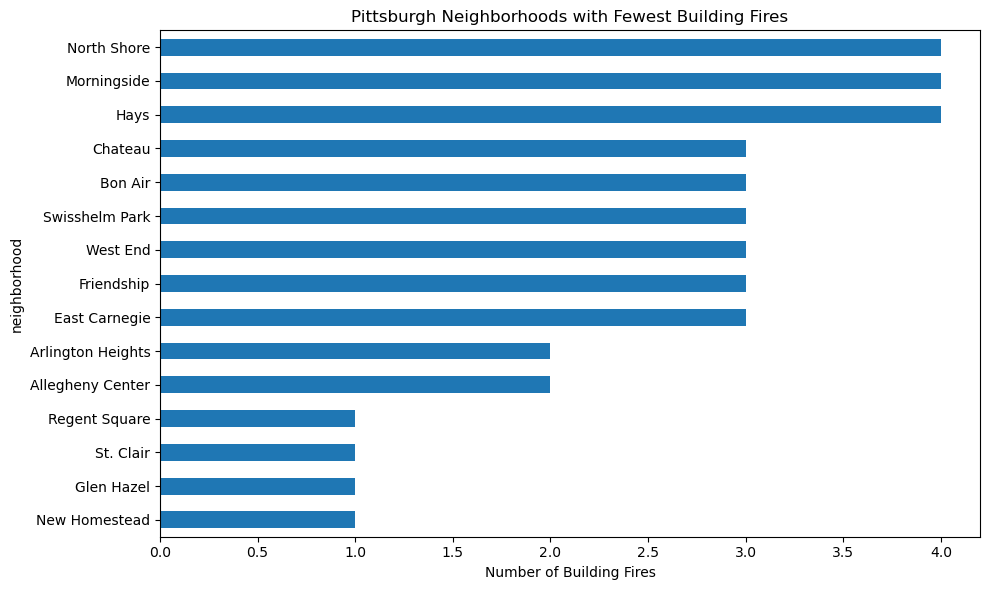

In [12]:
building_counts.head(15).plot(
    kind='barh',
    figsize=(10, 6),
    title='Pittsburgh Neighborhoods with Fewest Building Fires'
)
plt.xlabel('Number of Building Fires')
plt.tight_layout()
plt.show()

## Results
The neighborhoods with the fewest building fires are New Homestead, Glen Hazel, St. Clair, and Summer Hill (1 each). Several other smaller neighborhoods also have only 2–4 building fires over the full time period. Larger neighborhoods such as Knoxville and Carrick have substantially higher counts. By this metric, several smaller residential neighborhoods appear safer from building fires.

## Conclusion
Based on the available building fire data, New Homestead, Glen Hazel, St. Clair, and Summer Hill rank best. This is only one sub-metric. The final “best” neighborhood will be decided after combining this ranking with the group’s crime and EMS metrics.